<a href="https://colab.research.google.com/github/Abd33459/EdgeVisionN/blob/main/edgevision_gpu_object_detection_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 28.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [ ]:
import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("YOLO Version:", ultralytics.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cpu
CUDA Available: False
YOLO Version: 8.4.218


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
CUDA: True


In [ ]:
import torch

print("GPU Name:", torch.cuda.get_device_name(0))
print("GPU Memory:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
), "GB")

GPU Name: Tesla T4
GPU Memory: 14.56 GB


In [ ]:
from ultralytics import YOLO

# Load a lightweight pretrained YOLO model
model = YOLO("yolo11n.pt")

# Move model to NVIDIA GPU
model.to("cuda")

print("EdgeVision model loaded!")
print("Model:", "YOLO11n")
print("Device:", next(model.model.parameters()).device)

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
!pip install -q ultralytics

In [ ]:
from ultralytics import YOLO
import torch

model = YOLO("yolo11n.pt")
model.to("cuda")

print("EdgeVision model loaded!")
print("GPU:", torch.cuda.get_device_name(0))
print("Model device:", next(model.model.parameters()).device)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
EdgeVision model loaded!
GPU: Tesla T4
Model device: cuda:0



image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 11.9ms
Speed: 142.2ms preprocess, 11.9ms inference, 40.1ms postprocess per image at shape (1, 3, 640, 480)


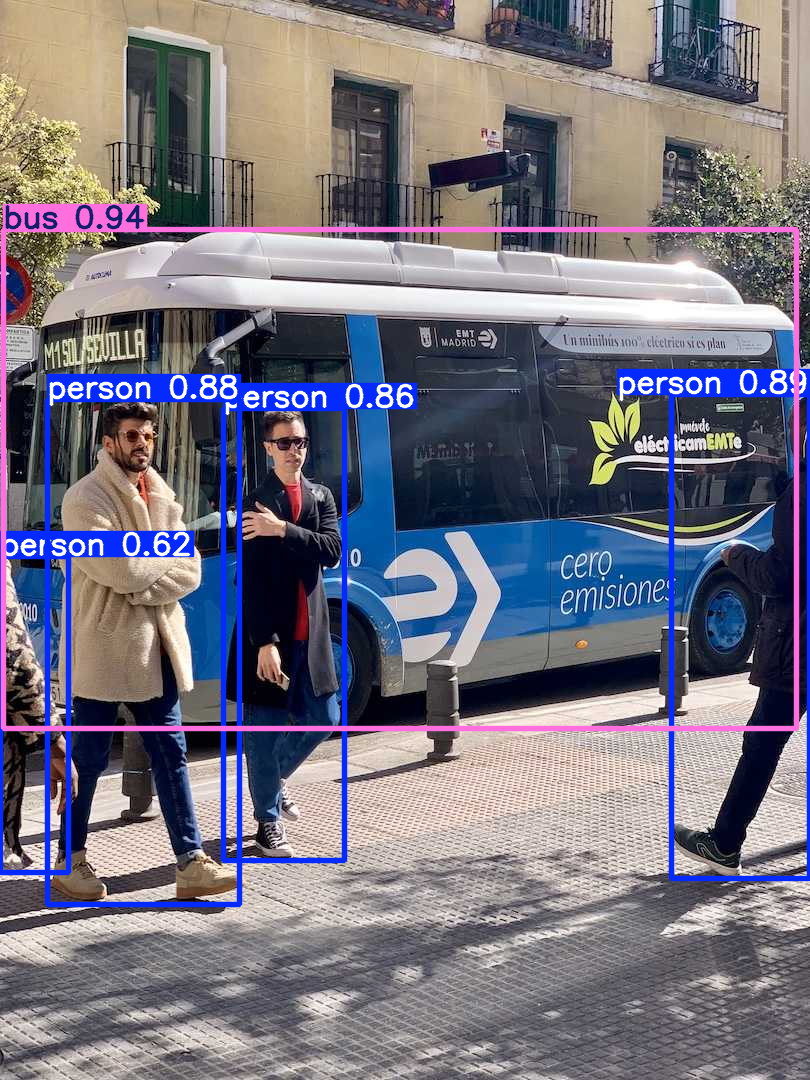

In [ ]:
from ultralytics import YOLO

# Sample image
image_url = "https://ultralytics.com/images/bus.jpg"

# Run object detection on NVIDIA GPU
results = model.predict(
    source=image_url,
    device=0,
    conf=0.25
)

# Display detected image
results[0].show()

In [ ]:
# Get first prediction
result = results[0]

# Count detected objects
from collections import Counter

class_names = [
    model.names[int(cls)]
    for cls in result.boxes.cls
]

object_counts = Counter(class_names)

print("EDGEVISION DETECTION REPORT")
print("---------------------------")

for name, count in object_counts.items():
    print(name, ":", count)

print("\nInference time:",
      result.speed["inference"], "ms")

print("Total detections:",
      len(result.boxes))

EDGEVISION DETECTION REPORT
---------------------------
bus : 1
person : 4

Inference time: 11.87447800003838 ms
Total detections: 5


In [ ]:
import time
import torch

# Prepare same image
image = "bus.jpg"

def benchmark(device, runs=10):
    model.to(device)

    # Warm-up
    for _ in range(3):
        model.predict(image, device=device, verbose=False)

    if device == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    for _ in range(runs):
        model.predict(image, device=device, verbose=False)

        if device == "cuda":
            torch.cuda.synchronize()

    end = time.perf_counter()

    return ((end - start) / runs) * 1000

cpu_time = benchmark("cpu")
gpu_time = benchmark("cuda")

print("EDGEVISION PERFORMANCE REPORT")
print("--------------------------------")
print(f"CPU average: {cpu_time:.2f} ms")
print(f"GPU average: {gpu_time:.2f} ms")

print(f"CPU/GPU speed ratio: {cpu_time/gpu_time:.2f}x")

EDGEVISION PERFORMANCE REPORT
--------------------------------
CPU average: 174.24 ms
GPU average: 41.06 ms
CPU/GPU speed ratio: 4.24x


In [ ]:
cpu_fps = 1000 / cpu_time
gpu_fps = 1000 / gpu_time

print("EDGEVISION FPS REPORT")
print("---------------------")
print(f"CPU FPS: {cpu_fps:.2f}")
print(f"GPU FPS: {gpu_fps:.2f}")

EDGEVISION FPS REPORT
---------------------
CPU FPS: 5.74
GPU FPS: 24.36


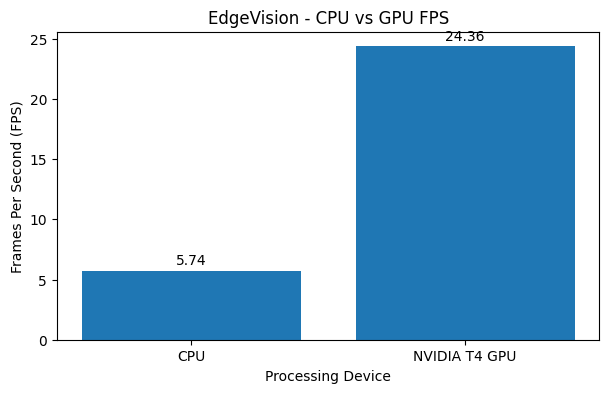

In [ ]:
import matplotlib.pyplot as plt

devices = ["CPU", "NVIDIA T4 GPU"]
fps = [cpu_fps, gpu_fps]

plt.figure(figsize=(7, 4))
plt.bar(devices, fps)

plt.title("EdgeVision - CPU vs GPU FPS")
plt.ylabel("Frames Per Second (FPS)")
plt.xlabel("Processing Device")

for i, value in enumerate(fps):
    plt.text(i, value + 0.5, f"{value:.2f}", ha="center")

plt.show()

In [ ]:
from ultralytics import YOLO
from collections import Counter

image_urls = [
    "https://ultralytics.com/images/bus.jpg",
    "https://ultralytics.com/images/zidane.jpg",
    "https://images.unsplash.com/photo-1500530855697-b586d89ba3ee?w=640"
]

for image_url in image_urls:
    results = model.predict(
        source=image_url,
        device=0,
        conf=0.25,
        verbose=False
    )

    result = results[0]

    names = [
        model.names[int(cls)]
        for cls in result.boxes.cls
    ]

    counts = Counter(names)

    print("\nIMAGE:", image_url.split("/")[-1])
    print("Detections:", dict(counts))
    print("Total objects:", len(result.boxes))
    print("Inference:", round(result.speed["inference"], 2), "ms")

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg

IMAGE: bus.jpg
Detections: {'bus': 1, 'person': 4}
Total objects: 5
Inference: 12.33 ms

IMAGE: zidane.jpg
Detections: {'person': 2, 'tie': 1}
Total objects: 3
Inference: 91.31 ms

IMAGE: photo-1500530855697-b586d89ba3ee?w=640
Detections: {}
Total objects: 0
Inference: 43.01 ms


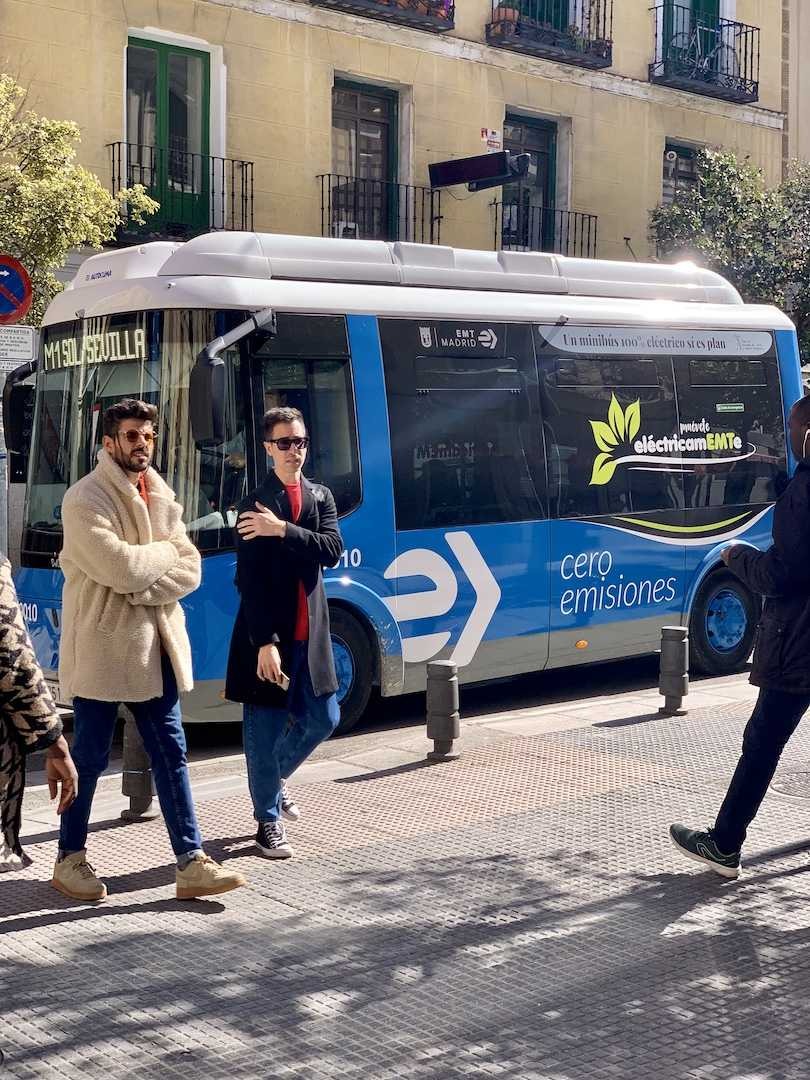

In [ ]:
from IPython.display import display
from PIL import Image

img = Image.open("bus.jpg")
display(img)

array([[[172, 161, 157],
        [172, 161, 157],
        [172, 161, 157],
        ...,
        [160, 150, 140],
        [161, 151, 141],
        [161, 151, 141]],

       [[172, 161, 157],
        [172, 161, 157],
        [172, 161, 157],
        ...,
        [160, 150, 140],
        [161, 151, 141],
        [161, 151, 141]],

       [[172, 161, 157],
        [172, 161, 157],
        [172, 161, 157],
        ...,
        [160, 150, 140],
        [161, 151, 141],
        [161, 151, 141]],

       ...,

       [[ 38,  36,  35],
        [ 39,  37,  36],
        [ 42,  40,  39],
        ...,
        [ 35,  34,  30],
        [ 34,  33,  29],
        [ 35,  34,  30]],

       [[ 38,  36,  35],
        [ 39,  37,  36],
        [ 42,  40,  39],
        ...,
        [ 38,  37,  33],
        [ 35,  34,  30],
        [ 33,  32,  28]],

       [[ 41,  39,  38],
        [ 42,  40,  39],
        [ 45,  43,  42],
        ...,
        [ 35,  34,  30],
        [ 37,  36,  32],
        [ 37,  36,  32]]], shape=(960, 640, 3), dtype=uint8)
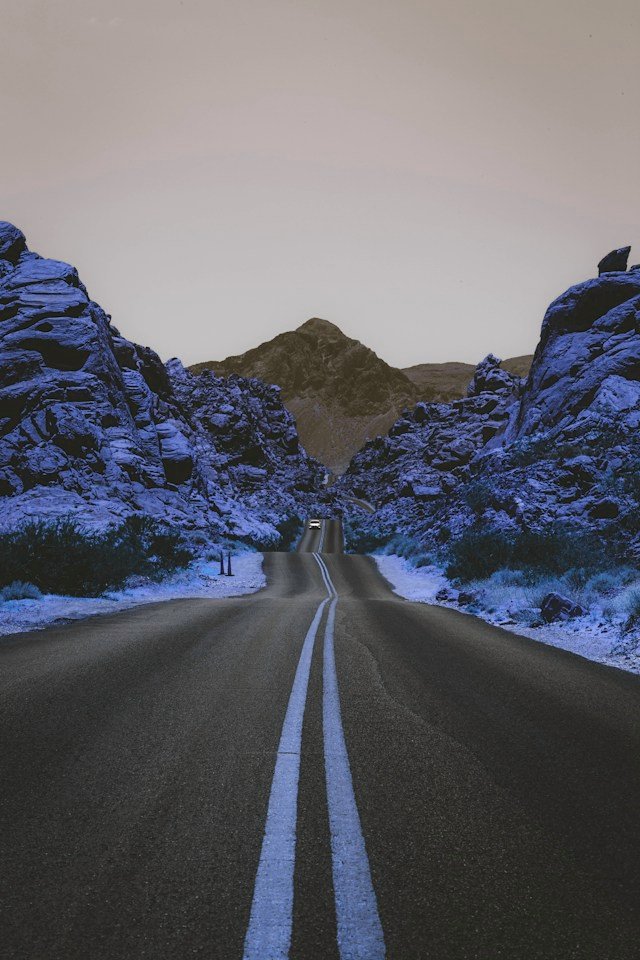

In [ ]:
from IPython.display import display
display(results[0].plot())

Detected objects:


array([[[172, 161, 157],
        [172, 161, 157],
        [172, 161, 157],
        ...,
        [160, 150, 140],
        [161, 151, 141],
        [161, 151, 141]],

       [[172, 161, 157],
        [172, 161, 157],
        [172, 161, 157],
        ...,
        [160, 150, 140],
        [161, 151, 141],
        [161, 151, 141]],

       [[172, 161, 157],
        [172, 161, 157],
        [172, 161, 157],
        ...,
        [160, 150, 140],
        [161, 151, 141],
        [161, 151, 141]],

       ...,

       [[ 38,  36,  35],
        [ 39,  37,  36],
        [ 42,  40,  39],
        ...,
        [ 35,  34,  30],
        [ 34,  33,  29],
        [ 35,  34,  30]],

       [[ 38,  36,  35],
        [ 39,  37,  36],
        [ 42,  40,  39],
        ...,
        [ 38,  37,  33],
        [ 35,  34,  30],
        [ 33,  32,  28]],

       [[ 41,  39,  38],
        [ 42,  40,  39],
        [ 45,  43,  42],
        ...,
        [ 35,  34,  30],
        [ 37,  36,  32],
        [ 37,  36,  32]]], shape=(960, 640, 3), dtype=uint8)
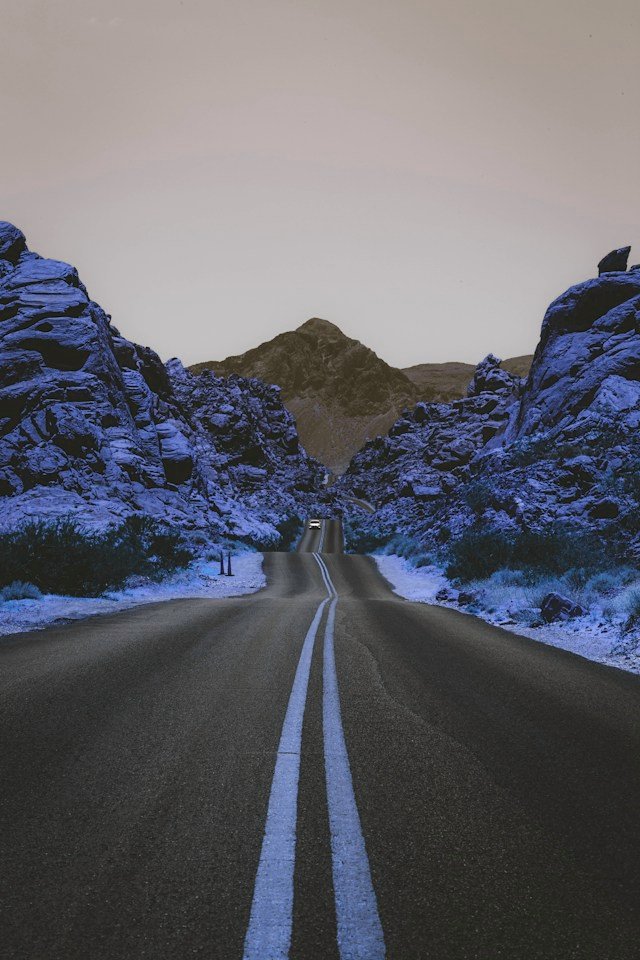

In [ ]:
third_image = image_urls[2]

result = model.predict(
    source=third_image,
    device=0,
    conf=0.10,
    verbose=False
)[0]

print("Detected objects:")

for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        model.names[class_id],
        round(confidence, 3)
    )

display(result.plot())

In [ ]:
test_image = "https://ultralytics.com/images/bus.jpg"

result = model.predict(
    source=test_image,
    device=0,
    conf=0.25,
    verbose=False
)[0]

print("Detected objects:", len(result.boxes))
display(result.plot())

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
Detected objects: 5


array([[[119, 146, 172],
        [121, 148, 174],
        [122, 152, 177],
        ...,
        [161, 171, 188],
        [160, 170, 187],
        [160, 170, 187]],

       [[120, 147, 173],
        [122, 149, 175],
        [123, 153, 178],
        ...,
        [161, 171, 188],
        [160, 170, 187],
        [160, 170, 187]],

       [[123, 150, 176],
        [124, 151, 177],
        [125, 155, 180],
        ...,
        [161, 171, 188],
        [160, 170, 187],
        [160, 170, 187]],

       ...,

       [[183, 182, 186],
        [179, 178, 182],
        [180, 179, 183],
        ...,
        [121, 111, 117],
        [113, 103, 109],
        [115, 105, 111]],

       [[165, 164, 168],
        [173, 172, 176],
        [187, 186, 190],
        ...,
        [102,  92,  98],
        [101,  91,  97],
        [103,  93,  99]],

       [[123, 122, 126],
        [145, 144, 148],
        [176, 175, 179],
        ...,
        [ 95,  85,  91],
        [ 96,  86,  92],
        [ 98,  88,  94]]

In [ ]:
print("=" * 40)
print("       EDGEVISION PROJECT REPORT")
print("=" * 40)

print("\nHARDWARE")
print("GPU: NVIDIA Tesla T4")

print("\nOBJECT DETECTION")
print("Bus image: 5 objects")
print("Zidane image: 3 objects")
print("Mountain image: 0 objects")

print("\nCPU vs GPU PERFORMANCE")
print(f"CPU: {cpu_time:.2f} ms")
print(f"GPU: {gpu_time:.2f} ms")
print(f"Speed ratio: {cpu_time/gpu_time:.2f}x")

print("\nFPS")
print(f"CPU: {cpu_fps:.2f}")
print(f"GPU: {gpu_fps:.2f}")

print("\nMODEL: YOLO11n")
print("FRAMEWORK: PyTorch + Ultralytics")
print("=" * 40)

       EDGEVISION PROJECT REPORT

HARDWARE
GPU: NVIDIA Tesla T4

OBJECT DETECTION
Bus image: 5 objects
Zidane image: 3 objects
Mountain image: 0 objects

CPU vs GPU PERFORMANCE
CPU: 174.24 ms
GPU: 41.06 ms
Speed ratio: 4.24x

FPS
CPU: 5.74
GPU: 24.36

MODEL: YOLO11n
FRAMEWORK: PyTorch + Ultralytics


In [ ]:
report = f"""
# EdgeVision
## GPU-Accelerated Object Detection & Performance Analyzer

### Technology Stack
- Python
- YOLO11n
- PyTorch
- Ultralytics
- NVIDIA CUDA
- Google Colab

### Hardware
- GPU: NVIDIA Tesla T4

### Object Detection Results

| Test Image | Objects Detected | Inference Time |
|---|---:|---:|
| Bus | 5 | 12.33 ms |
| Zidane | 3 | 91.31 ms |
| Mountain | 0 | 43.01 ms |

### CPU vs GPU Benchmark

| Metric | CPU | NVIDIA T4 GPU |
|---|---:|---:|
| Average prediction time | {cpu_time:.2f} ms | {gpu_time:.2f} ms |
| Approximate throughput | {cpu_fps:.2f} | {gpu_fps:.2f} |

Measured speed ratio: {cpu_time/gpu_time:.2f}x

### Project Features
- YOLO-based object detection
- Multiple image testing
- Object counting
- CPU vs GPU performance comparison
- FPS calculation
- Performance visualization

### Benchmark Notes
- 3 warm-up calls and 10 measured calls per device.
- Prediction time includes prediction pipeline overhead.
- FPS is calculated as 1000 divided by average prediction time.
- Results are preliminary and depend on hardware and workload.

### Conclusion
EdgeVision demonstrates object detection using YOLO11n
and compares CPU and NVIDIA GPU prediction performance.
"""

with open("EdgeVision_Report.md", "w") as file:
    file.write(report)

print("Report saved successfully!")
print("File: EdgeVision_Report.md")

Report saved successfully!
File: EdgeVision_Report.md


In [ ]:
import os

print("Report exists:", os.path.exists("EdgeVision_Report.md"))
print("OpenCV:", __import__("cv2").__version__)